# Advertising Sales Regression Analysis

## Business Scenario
A consumer goods company uses Television, Radio, and Newspaper advertising to promote its product. The objective is to understand how advertising spend influences Sales and predict future sales from planned advertising budgets.

## 1. Load the Dataset and Examine the Available Columns

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('advertising.csv')
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print('Dataset shape:', df.shape)
print('\nColumns:', list(df.columns))
display(df.head())
display(df.describe())

Dataset shape: (200, 4)

Columns: ['TV', 'Radio', 'Newspaper', 'Sales']


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## 2. Select Input Features and Target Variable

In [2]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

print('Input features:')
display(X.head())
print('Target variable:')
display(y.head())

Input features:


,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


Target variable:


0    22.1
1    10.4
2    12.0
3    16.5
4    17.9
Name: Sales, dtype: float64

## 3. Split the Data into Training and Testing Sets

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Training samples:', len(X_train))
print('Testing samples:', len(X_test))

Training samples: 160
Testing samples: 40


## 4. Build and Train the Linear Regression Model

In [4]:
model = LinearRegression()
model.fit(X_train, y_train)

print('Intercept:', model.intercept_)
print('Coefficients:')
display(pd.DataFrame({'Medium': X.columns, 'Coefficient': model.coef_}))

Intercept: 4.714126402214127
Coefficients:


,Medium,Coefficient
0,TV,0.054509
1,Radio,0.100945
2,Newspaper,0.004337


## 5. Predict Sales for Unseen Data

In [5]:
y_pred = model.predict(X_test)

prediction_results = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})
display(prediction_results.head(10))

,Actual Sales,Predicted Sales
0,16.9,17.034772
1,22.4,20.409740
2,21.4,23.723989
3,7.3,9.272785
4,24.7,21.682719
5,12.6,12.569402
6,22.3,21.081195
7,8.4,8.690350
8,16.5,17.237013
9,16.1,16.666575


## 6. Predict Sales for TV = 150, Radio = 20, Newspaper = 30

In [6]:
new_budget = pd.DataFrame({
    'TV': [150],
    'Radio': [20],
    'Newspaper': [30]
})

predicted_sales = model.predict(new_budget)[0]
print(f'Predicted Sales: {predicted_sales:.2f}')

Predicted Sales: 15.04


## 7. Evaluate the Model's Prediction Error

In [7]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

metrics = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R² Score'],
    'Value': [mae, mse, rmse, r2]
})
display(metrics)

,Metric,Value
0,MAE,1.274826
1,MSE,2.907757
2,RMSE,1.705215
3,R² Score,0.905901


## 8. Interpret the Model Coefficients

In [8]:
coef_df = pd.DataFrame({
    'Medium': X.columns,
    'Coefficient': model.coef_
}).sort_values('Coefficient', ascending=False)

display(coef_df)
print(f"Strongest impact: {coef_df.iloc[0]['Medium']}")
print(f"Least impact: {coef_df.iloc[-1]['Medium']}")
print(f"Model equation: Sales = {model.intercept_:.4f} + ({model.coef_[0]:.4f} × TV) + ({model.coef_[1]:.4f} × Radio) + ({model.coef_[2]:.4f} × Newspaper)")

,Medium,Coefficient
1,Radio,0.100945
0,TV,0.054509
2,Newspaper,0.004337


Strongest impact: Radio
Least impact: Newspaper
Model equation: Sales = 4.7141 + (0.0545 × TV) + (0.1009 × Radio) + (0.0043 × Newspaper)


## 9. Visualize Actual Sales vs Predicted Sales

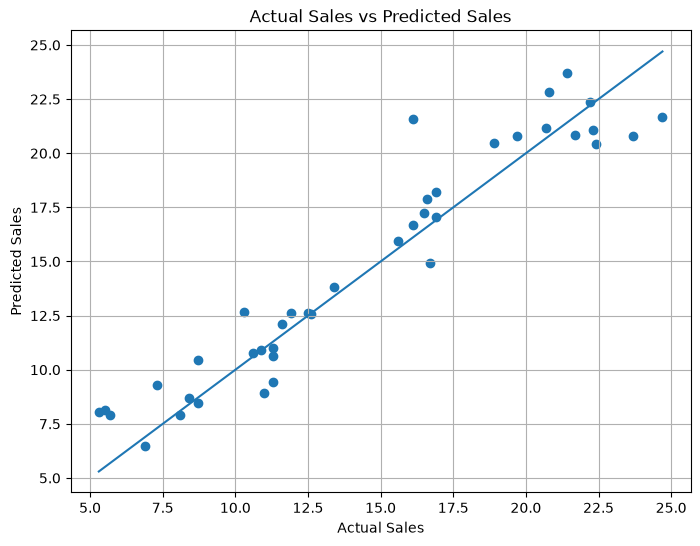

In [9]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()])
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual Sales vs Predicted Sales')
plt.grid(True)
plt.show()

## 10. Business Recommendation

Increase and prioritize investment in **Radio** advertising because it has the strongest positive coefficient and the largest estimated impact on sales per unit of advertising spend.

## 11. Technical Improvement

Use cross-validation and compare Linear Regression with models such as Random Forest or Gradient Boosting. Hyperparameter tuning can then be used to improve prediction accuracy.

## 12. Final Conclusion

The multiple linear regression model uses TV, Radio, and Newspaper advertising spend to predict Sales. For the planned budget of TV = 150, Radio = 20, and Newspaper = 30, the predicted sales are **15.04**. The model's test R² score is **0.9059**, with an RMSE of **1.7052**. Among the advertising channels, **Radio** has the strongest impact and **Newspaper** has the least impact based on the fitted coefficients.